# Optimizer Dynamics

## Setup

In [29]:
import time
from concurrent.futures import ThreadPoolExecutor, as_completed
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl
import polars.selectors as cs
import torch
from matplotlib.ticker import EngFormatter, MultipleLocator
from shared import SETUPS, preprocess_metrics_df, setup

from privacy_and_grokking.artifacts.cache import get_artifact_path
from privacy_and_grokking.artifacts.local import get_plots_dir
from privacy_and_grokking.artifacts.remote import checkpoint_artifact_path

In [2]:
setup()

In [3]:
runs_df = pl.read_parquet("../../cache/detailed-v1_runs.parquet")

In [4]:
metrics_df = pl.read_parquet("../../cache/detailed-v1_mlflow_export.parquet")
metrics_df = preprocess_metrics_df(metrics_df)

## Overview

In [5]:
metrics_df.group_by("title").agg(pl.col("step").max())

title,step
str,i64
null,150000
"""(VIII) ViT (CE) Baseline""",150000
"""(VII) ViT (CE) Grokking""",150000
"""(II) MLP (MSE) Baseline""",150000
"""(IV) MLP (CE) Baseline""",150000
"""(IX) MADD (CE) Grokking""",150000
"""(VI) ViT (MSE) Baseline""",150000
"""(I) MLP (MSE) Grokking""",150000
"""(III) MLP (CE) Grokking""",150000


In [6]:
metrics_df.describe()

statistic,run_id,run_name,step,timestamp,epoch,eval/generalization_gap,eval/loss/mse/overlap,eval/loss/mse_prob/overlap,eval/loss/ce/overlap,eval/nc/nc2_maximal_angle_equiangularity,eval/nc/nc2_equiangularity,eval/nc/nc1,eval/nc/nc2_maximal_angle_equiangularity_weights,eval/nc/nc4_test,eval/nc/nc4,eval/nc/nc2_equinorm,eval/nc/nc2_equinorm_weights,eval/nc/nc3,eval/nc/nc2_equiangularity_weights,eval/nc/rnc1/test,eval/nc/rnc1/train,eval/nc/rnc1/train_mean_test_variance_impl,eval/nc/rnc1/train_impl,eval/nc/rnc1/train_mean_test_variance,eval/nc/rnc1/test_impl,eval/grad_norm/fc2.weight,eval/grad_norm/fc1.bias,eval/grad_norm/fc3.bias,eval/grad_norm/fc1.weight,eval/grad_norm/fc2.bias,eval/grad_norm/fc3.weight,eval/grad_norm/total,eval/test/accuracy,eval/test/logits/incorrect/std,eval/test/logits/incorrect/mean,eval/test/logits/true_class/mean,…,eval/grad_norm/token_embed.weight,eval/grad_norm/attn.out_proj.bias,eval/grad_norm/head.weight,eval/grad_norm/mlp.2.bias,eval/grad_norm/mlp.2.weight,eval/grad_norm/pos_embed,eval/grad_norm/attn.in_proj_weight,eval/grad_norm/mlp.0.weight,eval/grad_norm/vit.encoder.layers.encoder_layer_0.mlp.0.weight,eval/grad_norm/vit.encoder.layers.encoder_layer_0.mlp.3.bias,eval/grad_norm/vit.encoder.layers.encoder_layer_0.self_attention.in_proj_weight,eval/grad_norm/vit.encoder.layers.encoder_layer_0.self_attention.in_proj_bias,eval/grad_norm/vit.conv_proj.bias,eval/grad_norm/vit.encoder.layers.encoder_layer_0.mlp.0.bias,eval/grad_norm/vit.conv_proj.weight,eval/grad_norm/vit.class_token,eval/grad_norm/vit.heads.head.weight,eval/grad_norm/vit.encoder.pos_embedding,eval/grad_norm/vit.encoder.layers.encoder_layer_0.self_attention.out_proj.bias,eval/grad_norm/vit.encoder.layers.encoder_layer_0.self_attention.out_proj.weight,eval/grad_norm/vit.heads.head.bias,eval/grad_norm/vit.encoder.layers.encoder_layer_0.mlp.3.weight,eval/weight_norm/vit.encoder.layers.encoder_layer_0.self_attention.out_proj.bias,eval/weight_norm/vit.encoder.layers.encoder_layer_0.mlp.0.weight,eval/weight_norm/vit.conv_proj.weight,eval/weight_norm/vit.heads.head.weight,eval/weight_norm/vit.class_token,eval/weight_norm/vit.encoder.layers.encoder_layer_0.self_attention.in_proj_bias,eval/weight_norm/vit.encoder.layers.encoder_layer_0.mlp.3.bias,eval/weight_norm/vit.encoder.layers.encoder_layer_0.self_attention.in_proj_weight,eval/weight_norm/vit.encoder.pos_embedding,eval/weight_norm/vit.heads.head.bias,eval/weight_norm/vit.encoder.layers.encoder_layer_0.self_attention.out_proj.weight,eval/weight_norm/vit.conv_proj.bias,eval/weight_norm/vit.encoder.layers.encoder_layer_0.mlp.0.bias,eval/weight_norm/vit.encoder.layers.encoder_layer_0.mlp.3.weight,title
str,str,str,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""count""","""20550""","""20550""",20550.0,"""20550""",2020.0,4050.0,4050.0,4050.0,4050.0,3898.0,3898.0,3898.0,3898.0,3898.0,3898.0,3898.0,3890.0,3890.0,3898.0,3898.0,3898.0,3898.0,3898.0,3898.0,3898.0,1608.0,1608.0,1608.0,1608.0,1608.0,1608.0,4050.0,4050.0,4050.0,4050.0,4050.0,…,814.0,814.0,814.0,814.0,814.0,814.0,814.0,814.0,1608.0,1608.0,1608.0,1608.0,1608.0,1608.0,1608.0,1608.0,1608.0,1608.0,1608.0,1608.0,1608.0,1608.0,1616.0,1616.0,1616.0,1616.0,1616.0,1616.0,1616.0,1616.0,1616.0,1616.0,1616.0,1616.0,1616.0,1616.0,"""18491"""
"""null_count""","""0""","""0""",0.0,"""0""",18530.0,16500.0,16500.0,16500.0,16500.0,16652.0,16652.0,16652.0,16652.0,16652.0,16652.0,16652.0,16660.0,16660.0,16652.0,16652.0,16652.0,16652.0,16652.0,16652.0,16652.0,18942.0,18942.0,18942.0,18942.0,18942.0,18942.0,16500.0,16500.0,16500.0,16500.0,16500.0,…,19736.0,19736.0,19736.0,19736.0,19736.0,19736.0,19736.0,19736.0,18942.0,18942.0,18942.0,18942.0,18942.0,18942.0,18942.0,18942.0,18942.0,18942.0,18942.0,18942.0,18942.0,18942.0,18934

In [7]:
metrics_df.columns

['run_id',
 'run_name',
 'step',
 'timestamp',
 'epoch',
 'eval/generalization_gap',
 'eval/loss/mse/overlap',
 'eval/loss/mse_prob/overlap',
 'eval/loss/ce/overlap',
 'eval/nc/nc2_maximal_angle_equiangularity',
 'eval/nc/nc2_equiangularity',
 'eval/nc/nc1',
 'eval/nc/nc2_maximal_angle_equiangularity_weights',
 'eval/nc/nc4_test',
 'eval/nc/nc4',
 'eval/nc/nc2_equinorm',
 'eval/nc/nc2_equinorm_weights',
 'eval/nc/nc3',
 'eval/nc/nc2_equiangularity_weights',
 'eval/nc/rnc1/test',
 'eval/nc/rnc1/train',
 'eval/nc/rnc1/train_mean_test_variance_impl',
 'eval/nc/rnc1/train_impl',
 'eval/nc/rnc1/train_mean_test_variance',
 'eval/nc/rnc1/test_impl',
 'eval/grad_norm/fc2.weight',
 'eval/grad_norm/fc1.bias',
 'eval/grad_norm/fc3.bias',
 'eval/grad_norm/fc1.weight',
 'eval/grad_norm/fc2.bias',
 'eval/grad_norm/fc3.weight',
 'eval/grad_norm/total',
 'eval/test/accuracy',
 'eval/test/logits/incorrect/std',
 'eval/test/logits/incorrect/mean',
 'eval/test/logits/true_class/mean',
 'eval/test/logits/

## Collecting Trajectories/Distances

In [30]:
def fetch_weights(run_id: str, step: int, attempts: int = 3) -> Path:
    path = f"{checkpoint_artifact_path(step)}/model.pth"
    for i in range(attempts):
        try:
            return get_artifact_path(run_id, path, timeout=15.0)
        except Exception:
            if i == attempts - 1:
                raise
            time.sleep(1.5 ** i)

jobs = []
run_ids = metrics_df.filter(pl.col("title").is_not_null())["run_id"].unique().to_list()
for run_id in run_ids:
    run_df = metrics_df.filter(pl.col("run_id") == run_id)
    steps = run_df.drop_nulls(subset=["optim/global_grad_norm"])["step"].unique().to_list()
    steps.append(run_df["step"].max()) # Ensure the last step is included
    jobs.extend((run_id, int(s)) for s in sorted(steps))

MAX_WORKERS = 4
weight_maps = {rid: {} for rid in run_ids}
with ThreadPoolExecutor(max_workers=MAX_WORKERS) as pool:
    futures = {pool.submit(fetch_weights, rid, s): (rid, s) for rid, s in jobs}
    for n, fut in enumerate(as_completed(futures), start=1):
        rid, step = futures[fut]
        weight_maps[rid][step] = fut.result()
        print(f"[{n}/{len(jobs)}] run={rid} step={step}", end="\r")

In [37]:
from sklearn.decomposition import IncrementalPCA

In [38]:
def state_dict_to_tensor(sd):
    tensors = [v.flatten().float() for v in sd.values() if torch.is_floating_point(v)]
    return torch.cat(tensors)

frames = []
for run_id, step_map in weight_maps.items():
    initial_weights = None
    last_weights = None
    entries = []
    steps = sorted(step_map.keys())
    all_weights = []
    for step in steps:
        path = step_map[step]
        weights = state_dict_to_tensor(torch.load(path, weights_only=True, map_location="cpu"))
        if initial_weights is None:
            initial_weights = weights
        if last_weights is None:
            last_weights = weights

        all_weights.append(weights)

        distance_from_start = torch.dist(initial_weights, weights).item()
        distance_from_last = torch.dist(last_weights, weights).item()
        entries.append({
            "run_id": run_id,
            "step": step,
            "distance_from_start": distance_from_start,
            "distance_from_last": distance_from_last,
        })
        last_weights = weights

    X = torch.stack(all_weights).numpy()   # (N, D), float32

    # IncrementalPCA rechnet intern float64: ~64 MB pro Batch anpeilen.
    batch_size = max(2, min(64, (64 * 1024**2) // (X.shape[1] * 8)))
    ipca = IncrementalPCA(n_components=2, batch_size=batch_size)
    coords = ipca.fit_transform(X)          # (N, 2)

    frames.append(
        pl.DataFrame(entries).with_columns(
            pl.Series("pc1", coords[:, 0]),
            pl.Series("pc2", coords[:, 1]),
        )
    )
    print(run_id, "EVR:", ipca.explained_variance_ratio_)

trajectory_df = pl.concat(frames)

6e6c6cfc9f404b1d88b470d577814440 EVR: [0.85826378 0.03646372]
01bcc0bb502940938e06ceff289b59c1 EVR: [0.6228875  0.16076411]
df8757baec5c49e98a59be051e5a3af7 EVR: [0.5059646  0.18521201]
2143636bf7d1447e9fa8ef6f107c5d03 EVR: [0.82466097 0.03792811]
0d450ef284334016a919d902a67618f9 EVR: [0.60685197 0.14166836]
643c7a30949a4917ac3214c40095a6fb EVR: [0.51922155 0.1618565 ]
9eb2e9459c1242229eccabecc5f35a59 EVR: [0.6776078  0.17634155]
69f293b6f5094f9bb0b20abd4e255ef9 EVR: [0.38797464 0.1726732 ]
1661a76b7fa34c1ab27673ccc83e293e EVR: [0.15537232 0.08078159]


In [39]:
trajectory_df.head(10)

run_id,step,distance_from_start,distance_from_last,pc1,pc2
str,i64,f64,f64,f64,f64
"""6e6c6cfc9f404b1d88b470d5778144…",0,0.0,0.0,-46.491532,-8.107224
"""6e6c6cfc9f404b1d88b470d5778144…",100,4.740066,4.740066,-46.176845,-7.322667
"""6e6c6cfc9f404b1d88b470d5778144…",200,4.744795,0.110045,-46.090504,-7.31669
"""6e6c6cfc9f404b1d88b470d5778144…",300,4.748941,0.103739,-46.004537,-7.311059
"""6e6c6cfc9f404b1d88b470d5778144…",400,4.755122,0.101465,-45.918571,-7.305606
"""6e6c6cfc9f404b1d88b470d5778144…",500,4.763377,0.10138,-45.83275,-7.300117
"""6e6c6cfc9f404b1d88b470d5778144…",600,4.773537,0.099803,-45.746954,-7.294718
"""6e6c6cfc9f404b1d88b470d5778144…",700,4.785449,0.098655,-45.661336,-7.289136
"""6e6c6cfc9f404b1d88b470d5778144…",800,4.799071,0.098418,-45.57584,-7.283476


In [40]:
trajectory_df.write_parquet("../../cache/detailed-v1_trajectory.parquet")

## Analysis

In [41]:
trajectory_df = pl.read_parquet("../../cache/detailed-v1_trajectory.parquet")

In [43]:
PLOTS = get_plots_dir()

In [53]:
import math

C:\Users\Qunor\AppData\Local\Temp\ipykernel_22968\2830504643.py:30: DeprecationWarning: `is_in` with a collection of the same datatype is ambiguous and deprecated.
Please use `implode` to return to previous behavior.

See https://github.com/pola-rs/polars/issues/22149 for more information.
  df_trajectory = trajectory_df.filter(pl.col("run_id").is_in(


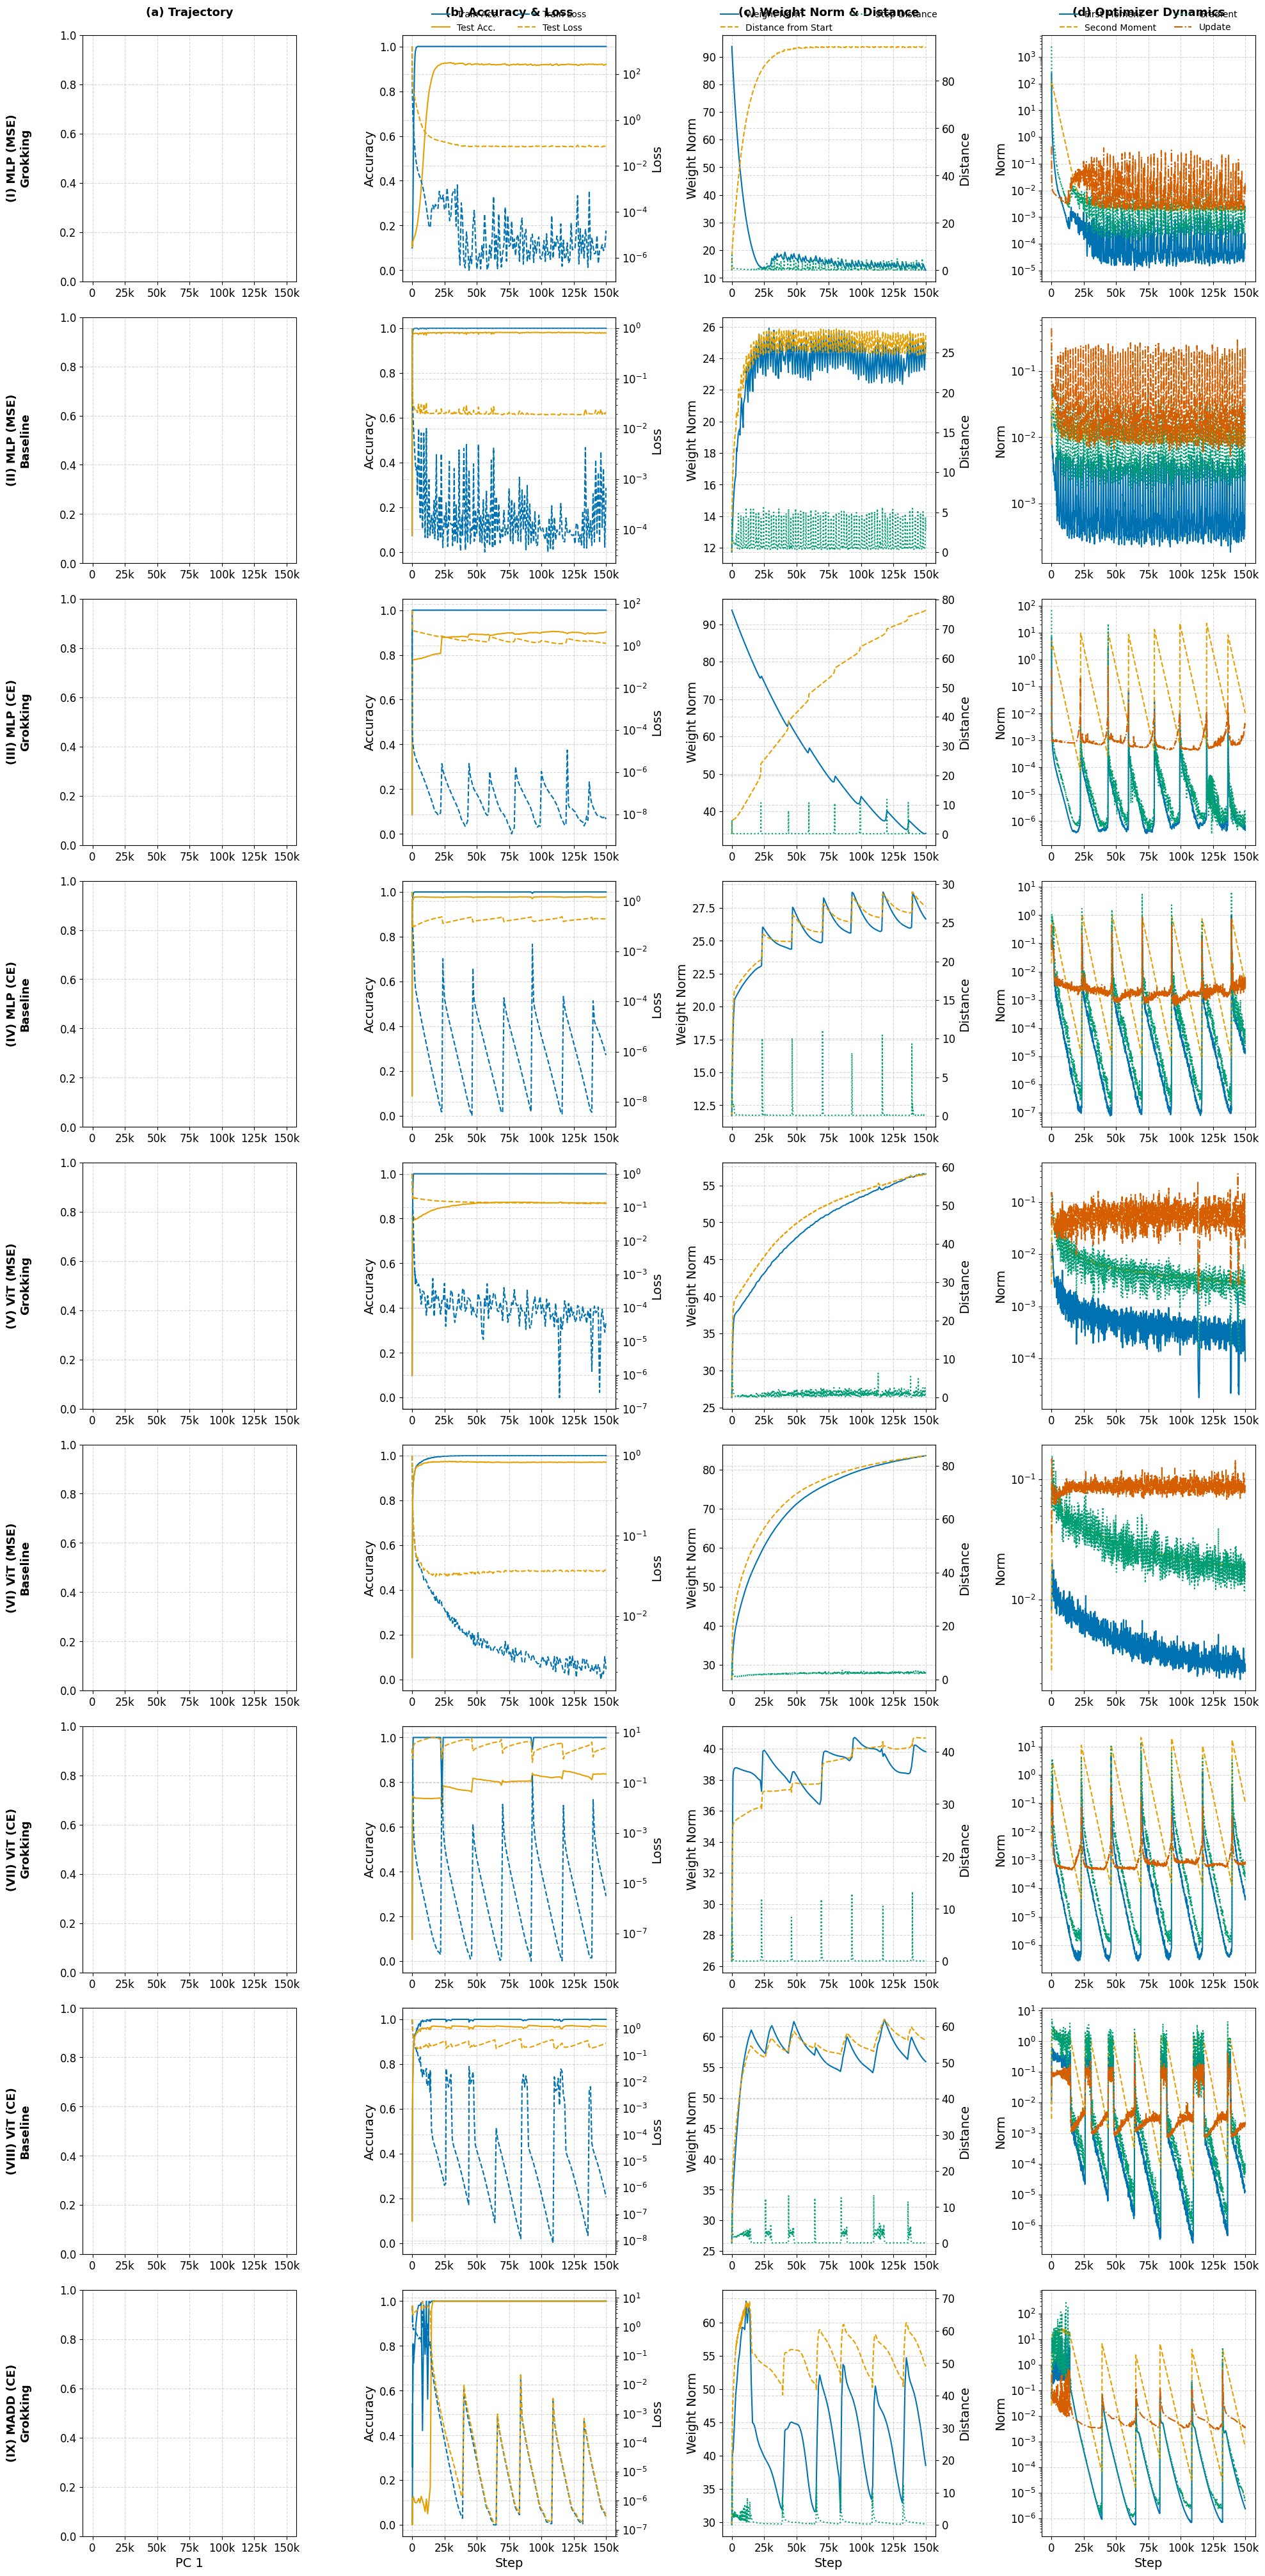

In [54]:
N_ROWS = len(SETUPS)
N_COLS = 4
TITLES = list(SETUPS.values())
COLORS = plt.rcParams["axes.prop_cycle"].by_key()["color"]
LINES = plt.rcParams["axes.prop_cycle"].by_key()["linestyle"]

fig, axes = plt.subplots(N_ROWS, N_COLS, figsize=(5 * N_COLS, 4.5 * N_ROWS))

def style_step_axis(ax, df):
    """Apply the shared step-axis limits, locator, and formatter."""
    step_max = df["step"].max()
    ax.set_xlim(-0.05 * step_max, step_max * 1.05)
    ax.xaxis.set_major_locator(MultipleLocator(25_000 if step_max > 50_000 else 10_000))
    ax.xaxis.set_major_formatter(EngFormatter(unit="", places=0, sep=""))

for row in range(N_ROWS):
    title = TITLES[row]
    ax = axes[row]

    df = (
        metrics_df
        .filter(pl.col("title") == title)
        .group_by(["step"])
        .agg([
            cs.numeric().exclude("step").mean().name.suffix("_mean"),
            cs.numeric().exclude("step").std().name.suffix("_std"),
        ])
        .sort(["step"])
    )
    df_trajectory = trajectory_df.filter(pl.col("run_id").is_in(
        metrics_df.filter(pl.col("title") == title)["run_id"].unique()
    ))

    if df.is_empty():
        for a in ax:
            a.text(0.5, 0.5, "N/A", ha="center", va="center")
        continue

    # # Row title (rotated, left of the first panel).
    ax[0].annotate(
        title,
        xy=(-0.30, 0.5),
        xycoords="axes fraction",
        fontsize=13,
        fontweight="bold",
        ha="center",
        va="center",
        rotation=90,
    )

    for a in ax:
        style_step_axis(a, df)

    if row == N_ROWS - 1:
        ax[0].set_xlabel("PC 1")
        for i in range(1, N_COLS):
            ax[i].set_xlabel("Step")

    # (a) Trajectory
    # plot_region(ax[1], df, "eval/nc/nc2_equinorm", "Equin.", color=COLORS[0])
    # plot_region(ax[1], df, "eval/nc/nc2_equiangularity", "Equiang.", color=COLORS[1])
    # plot_region(ax[1], df, "eval/nc/nc2_maximal_angle_equiangularity", "Max. Angle", color=COLORS[2])
    # ax[1].set_ylabel("NC2")
    if row == 0:
        ax[0].set_title("(a) Trajectory", fontsize=13, fontweight="bold", pad=22)
    #     h1, l1 = ax[1].get_legend_handles_labels()
    #     ax[1].legend(h1, l1, loc="lower center", bbox_to_anchor=(0.5, 0.98), ncol=len(l1), frameon=False, fontsize=10)
    # # ax[1].legend()

    # (b) Accuracy & Loss
    d = df[["step", "eval/train/accuracy_mean"]].drop_nulls()
    ax[1].plot(d["step"], d["eval/train/accuracy_mean"], label="Train Acc.", color=COLORS[0], linestyle=LINES[0])
    d = df[["step", "eval/test/accuracy_mean"]].drop_nulls()
    ax[1].plot(d["step"], d["eval/test/accuracy_mean"], label="Test Acc.", color=COLORS[1], linestyle=LINES[0])
    ax[1].set_ylim(bottom=-0.05, top=1.05)
    ax[1].set_ylabel("Accuracy")

    twin_b = ax[1].twinx()
    loss = "mse" if "mse" in title.lower() else "cross_entropy"
    d = df[["step", f"eval/train/loss/{loss}/mean_mean"]].drop_nulls()
    twin_b.plot(d["step"], d[f"eval/train/loss/{loss}/mean_mean"], label="Train Loss", color=COLORS[0], linestyle=LINES[1])
    d = df[["step", f"eval/test/loss/{loss}/mean_mean"]].drop_nulls()
    twin_b.plot(d["step"], d[f"eval/test/loss/{loss}/mean_mean"], label="Test Loss", color=COLORS[1], linestyle=LINES[1])
    twin_b.set_ylabel("Loss")
    twin_b.set_yscale("log")
    if row == 0:
        ax[1].set_title("(b) Accuracy & Loss", fontsize=13, fontweight="bold", pad=22)
        h1, l1 = ax[1].get_legend_handles_labels()
        h2, l2 = twin_b.get_legend_handles_labels()
        ax[1].legend(h1 + h2, l1 + l2, loc="lower center", bbox_to_anchor=(0.5, 0.98), ncol=math.ceil(len(l1 + l2) / 2), frameon=False, fontsize=10)


    # (c) Weight Norm & Distance
    # plot_region(ax[2], df, "eval/nc/nc2_equinorm_weights", "Equin.", color=COLORS[0])
    # plot_region(ax[2], df, "eval/nc/nc2_equiangularity_weights", "Equiang.", color=COLORS[1])
    # plot_region(ax[2], df, "eval/nc/nc2_maximal_angle_equiangularity_weights", "Max. Angle", color=COLORS[2])
    # ax[2].set_ylabel("NC2 Weights")
    d = df[["step", "eval/weight_norm/total_mean"]].drop_nulls()
    ax[2].plot(d["step"], d["eval/weight_norm/total_mean"], label="Weight Norm", color=COLORS[0], linestyle=LINES[0])
    ax[2].set_ylabel("Weight Norm")

    twin_c = ax[2].twinx()
    twin_c.plot(df_trajectory["step"], df_trajectory["distance_from_start"], label="Distance from Start", color=COLORS[1], linestyle=LINES[1])
    twin_c.plot(df_trajectory["step"], df_trajectory["distance_from_last"], label="Step Distance", color=COLORS[2], linestyle=LINES[2])
    twin_c.set_ylabel("Distance")
    if row == 0:
        ax[2].set_title("(c) Weight Norm & Distance", fontsize=13, fontweight="bold", pad=22)
        h1, l1 = ax[2].get_legend_handles_labels()
        h2, l2 = twin_c.get_legend_handles_labels()
        ax[2].legend(h1 + h2, l1 + l2, loc="lower center", bbox_to_anchor=(0.5, 0.98), ncol=math.ceil(len(l1 + l2) / 2), frameon=False, fontsize=10)
    # # ax[2].legend()

    # (d) Optimizer Dynamics
    ax[3].set_ylabel("Norm")
    d = df[["step", "optim/global_mt_norm_mean"]].drop_nulls()
    ax[3].plot(d["step"], d["optim/global_mt_norm_mean"], label="First Moment", color=COLORS[0], linestyle=LINES[0])
    d = df[["step", "optim/global_sqrt_vt_norm_mean"]].drop_nulls()
    ax[3].plot(d["step"], d["optim/global_sqrt_vt_norm_mean"], label="Second Moment", color=COLORS[1], linestyle=LINES[1])
    d = df[["step", "optim/global_grad_norm_mean"]].drop_nulls()
    ax[3].plot(d["step"], d["optim/global_grad_norm_mean"], label="Gradient", color=COLORS[2], linestyle=LINES[2])
    d = df[["step", "optim/global_update_norm_mean"]].drop_nulls()
    ax[3].plot(d["step"], d["optim/global_update_norm_mean"], label="Update", color=COLORS[3], linestyle=LINES[3])
    ax[3].set_yscale("log")
    if row == 0:
        ax[3].set_title("(d) Optimizer Dynamics", fontsize=13, fontweight="bold", pad=22)
        h1, l1 = ax[3].get_legend_handles_labels()
        ax[3].legend(h1, l1, loc="lower center", bbox_to_anchor=(0.5, 0.98), ncol=math.ceil(len(l1) / 2), frameon=False, fontsize=10)

plt.tight_layout()
fig.savefig(PLOTS / f"detailed_{str(date.today())}.pdf", format="pdf", bbox_inches="tight")
